Missing values:
 year                 0
cpi                  0
gdp_growth           0
gdp_usd              0
unemployment         0
capital_formation    0
exports_pct_gdp      0
imports_pct_gdp      0
gov_consumption      0
current_account      0
dtype: int64

Summary Statistics:
           year     cpi  gdp_growth       gdp_usd  unemployment  \
count    34.00   34.00       34.00  3.400000e+01         34.00   
mean   2007.50  101.21        6.13  1.472502e+12          7.29   
std       9.96   61.30        2.87  1.119890e+12          0.96   
min    1991.00   26.13       -5.78  2.701053e+11          4.17   
25%    1999.25   52.77        4.93  4.612147e+11          7.57   
50%    2007.50   77.43        6.73  1.207816e+12          7.63   
75%    2015.75  152.24        7.91  2.246995e+12          7.67   
max    2024.00  227.60        9.69  3.909892e+12          7.86   

       capital_formation  exports_pct_gdp  imports_pct_gdp  gov_consumption  \
count              34.00            34.00   

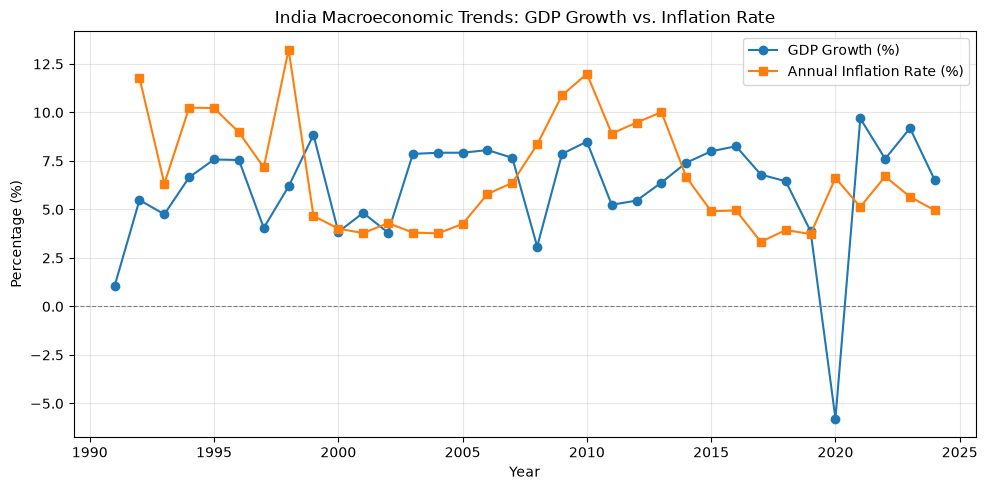

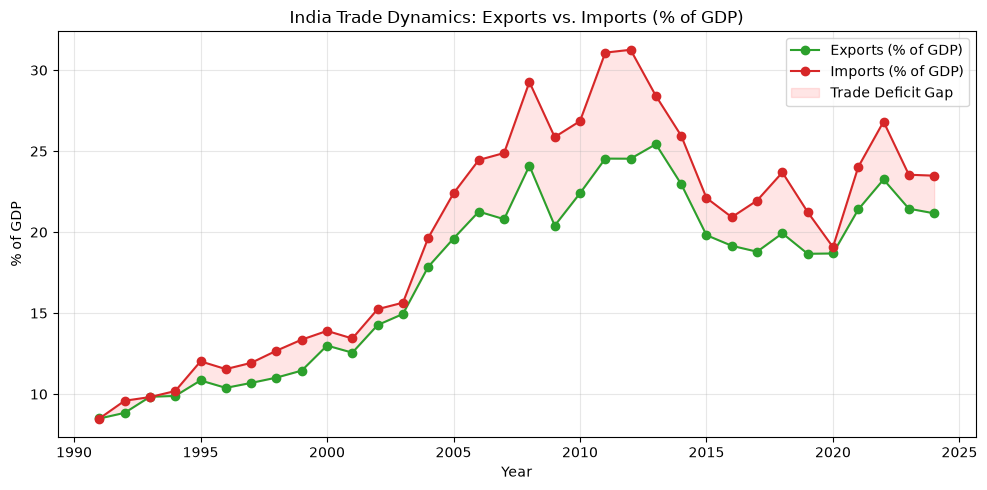

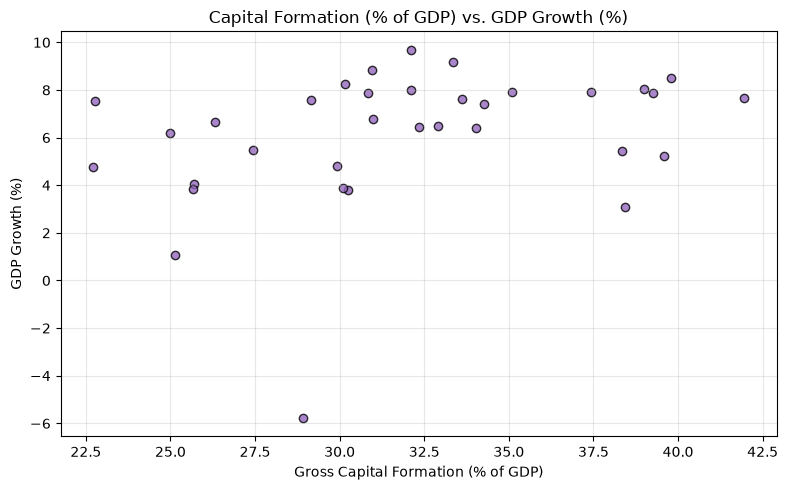

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_csv('india_macro_worldbank.csv') # use pd.read_excel('file.xlsx') if it's an Excel file
df = df.sort_values('year').reset_index(drop=True)

# 2. Check missing values & basic stats
print("Missing values:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe().round(2))

# 3. Feature Engineering (Great talking point for interviews!)
df['inflation_rate'] = df['cpi'].pct_change() * 100
df['trade_balance_pct_gdp'] = df['exports_pct_gdp'] - df['imports_pct_gdp']
df['gdp_trillion_usd'] = df['gdp_usd'] / 1e12

# 4. Chart 1: GDP Growth vs. Calculated Inflation Rate
plt.figure(figsize=(10, 5))
plt.plot(df['year'], df['gdp_growth'], label='GDP Growth (%)', marker='o', color='#1f77b4')
plt.plot(df['year'], df['inflation_rate'], label='Annual Inflation Rate (%)', marker='s', color='#ff7f0e')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('India Macroeconomic Trends: GDP Growth vs. Inflation Rate')
plt.xlabel('Year')
plt.ylabel('Percentage (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('1_gdp_vs_inflation.png', dpi=300)
plt.show()

# 5. Chart 2: Exports vs. Imports (% of GDP) & Trade Openness
plt.figure(figsize=(10, 5))
plt.plot(df['year'], df['exports_pct_gdp'], label='Exports (% of GDP)', marker='o', color='#2ca02c')
plt.plot(df['year'], df['imports_pct_gdp'], label='Imports (% of GDP)', marker='o', color='#d62728')
plt.fill_between(df['year'], df['exports_pct_gdp'], df['imports_pct_gdp'], color='red', alpha=0.1, label='Trade Deficit Gap')
plt.title('India Trade Dynamics: Exports vs. Imports (% of GDP)')
plt.xlabel('Year')
plt.ylabel('% of GDP')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('2_trade_dynamics.png', dpi=300)
plt.show()

# 6. Chart 3: Investment (Capital Formation) vs. GDP Growth Correlation
plt.figure(figsize=(8, 5))
plt.scatter(df['capital_formation'], df['gdp_growth'], color='#9467bd', alpha=0.8, edgecolors='k')
plt.title('Capital Formation (% of GDP) vs. GDP Growth (%)')
plt.xlabel('Gross Capital Formation (% of GDP)')
plt.ylabel('GDP Growth (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('3_investment_vs_growth.png', dpi=300)
plt.show()